# Data Understanding - Ordeño y concentrado

**Equipo PINU**

Este EDA lee dos archivos ya preparados: `Data/dataset_vacas_anonimo.csv`, que reúne los reportes csv y los históricos xlsx de ordeño, y `Data/dataset_concentrado_anonimo.csv`, que reúne los xlsx de concentrado consumido. El análisis conjunto se centra en 2025-2026, periodo en el que coinciden ambas fuentes.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
plt.style.use("seaborn-v0_8-whitegrid")

# Funciona si Jupyter se abre desde la raíz del proyecto o una subcarpeta
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "Data" / "dataset_vacas_anonimo.csv").is_file()), None)
if raiz is None:
    raise FileNotFoundError("No se encontró Data/dataset_vacas_anonimo.csv")

ordeno = pd.read_csv(
    raiz / "Data" / "dataset_vacas_anonimo.csv",
    dtype={"id_vaca": "string", "misc_eo_po": "string"},
    low_memory=False,
)
concentrado = pd.read_csv(
    raiz / "Data" / "dataset_concentrado_anonimo.csv",
    dtype={"id_vaca": "string"},
    low_memory=False,
)
columnas_originales = ordeno.columns.tolist()
duplicados_exactos = int(ordeno.duplicated().sum())

In [2]:
# Los reportes csv y el histórico xlsx usan formatos de fecha y duración distintos
texto = ordeno["main_hora_de_inicio"].astype("string").str.strip()
es_xlsx = texto.str.fullmatch(r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}", na=False)
texto_csv = (texto.str.lower()
            .str.replace("a. m.", "AM", regex=False)
            .str.replace("p. m.", "PM", regex=False))
ordeno["inicio"] = pd.to_datetime(texto_csv, format="%d/%m/%Y %I:%M %p", errors="coerce")
ordeno.loc[es_xlsx, "inicio"] = pd.to_datetime(
    texto[es_xlsx], format="%Y-%m-%d %H:%M:%S", errors="coerce"
)
ordeno["origen"] = np.where(es_xlsx, "histórico XLSX", "reporte CSV")
ordeno["fecha"] = ordeno["inicio"].dt.normalize()
ordeno["produccion_kg"] = pd.to_numeric(ordeno["main_produccion_kg"], errors="coerce")

partes = ordeno["main_duracion_mm_ss"].astype("string").str.extract(
    r"^(?:(\d+):)?(\d{1,2}):([0-5]\d)$"
)
horas = pd.to_numeric(partes[0], errors="coerce").fillna(0)
minutos = pd.to_numeric(partes[1], errors="coerce")
segundos = pd.to_numeric(partes[2], errors="coerce")
ordeno["duracion_min"] = horas * 60 + minutos + segundos / 60
ordeno.loc[partes[0].notna() & minutos.gt(59), "duracion_min"] = np.nan

es_ordeno_csv = ordeno["main_accion"].astype("string").str.strip().str.casefold().eq("ordeño").fillna(False)
ordeno["es_sesion"] = es_ordeno_csv | (
    es_xlsx & ordeno["main_accion"].isna()
    & ordeno["estado_numero_de_ordeno"].notna()
    & ordeno["produccion_kg"].notna()
)

# Si una sesión aparece en csv y xlsx con la misma vaca, minuto de inicio,
# producción y duración, se descarta la copia en csv y se conserva sólo la
# fila xlsx, pues esta es es más precisa en cuanto a los segundos de la hora
# de inicio.
llaves = pd.DataFrame({
    "id_vaca": ordeno["id_vaca"],
    "minuto": ordeno["inicio"].dt.floor("min"),
    "produccion_kg": ordeno["produccion_kg"],
    "duracion_seg": (ordeno["duracion_min"] * 60).round().astype("Int64"),
})
llaves_xlsx = llaves.loc[es_xlsx].drop_duplicates().assign(en_xlsx=True)
coincide = llaves.merge(
    llaves_xlsx, on=list(llaves.columns), how="left", sort=False
)["en_xlsx"].eq(True).to_numpy(dtype=bool)
ordeno["copia_csv"] = es_ordeno_csv & coincide

sesiones = ordeno.loc[
    ordeno["es_sesion"] & ~ordeno["copia_csv"]
    & ordeno["inicio"].ge("2025-01-01") & ordeno["inicio"].lt("2027-01-01")
].copy()
concentrado["hora_evento"] = pd.to_datetime(
    concentrado["hora_evento"], format="%Y-%m-%d %H:%M:%S", errors="coerce"
)
concentrado["fecha"] = concentrado["hora_evento"].dt.normalize()
concentrado["consumido"] = pd.to_numeric(concentrado["consumido"], errors="coerce")

print(f"Sesiones de producción 2025-2026: {len(sesiones):,}")
print(f"Copias CSV de sesiones XLSX excluidas: {ordeno['copia_csv'].sum():,}")

Sesiones de producción 2025-2026: 130,045
Copias CSV de sesiones XLSX excluidas: 5,285


## 1. Visualizar y consultar los datos

Se usan los dos archivos anonimizados, el de vacas y concentrado. En el primero cada fila corresponde a una visita o sesión de producción, mientras que en el segundo, corresponde a un registro de consumo.

In [3]:
display(sesiones[["id_vaca", "inicio", "produccion_kg", "duracion_min",
                "estado_patada", "misc_eo_po"]].head())
display(concentrado[["id_vaca", "hora_evento", "consumido"]].head())

,id_vaca,inicio,produccion_kg,duracion_min,estado_patada,misc_eo_po
0,6eca6a01,2025-03-01 05:37:00,23.96,9.966667,NaN,486cc6e5
1,6eca6a01,2025-03-01 19:15:00,17.20,6.85,DI,486cc6e5
2,6eca6a01,2025-03-02 02:24:00,11.13,7.383333,NaN,486cc6e5
3,6eca6a01,2025-03-02 19:51:00,20.64,8.483333,NaN,486cc6e5
4,6eca6a01,2025-03-03 06:00:00,9.59,5.083333,NaN,486cc6e5


,id_vaca,hora_evento,consumido
0,cf184e31,2026-01-28 11:00:00,0.394
1,cf184e31,2026-01-28 06:00:00,0.535
2,cf184e31,2026-01-28 01:00:00,1.905
3,cf184e31,2026-01-27 18:00:00,1.274
4,cf184e31,2026-01-27 06:00:00,2.320


## 2. Tipos de datos, nulos y duplicados

Se requiere normalizar pues las fechas y duraciones llegan en formatos distintos al combinar las 2 fuentes de sesiones de producción csv y xlsx. También hay sesiones repetidas de 2025 registradas en los csv y en los xlsx.

In [4]:
display(ordeno[["main_hora_de_inicio", "inicio", "main_duracion_mm_ss",
                "duracion_min", "main_produccion_kg", "produccion_kg",
                "main_accion", "misc_eo_po"]].dtypes.to_frame("tipo"))
display(concentrado[["id_vaca", "hora_evento", "consumido"]].dtypes.to_frame("tipo"))

calidad = pd.DataFrame({
    "indicador": [
        "Fechas de ordeño no interpretables", "Duraciones no interpretables",
        "Fechas de concentrado no interpretables", "Consumos faltantes",
        "Duplicados exactos en ordeño", "Copias CSV de sesiones XLSX",
    ],
    "registros": [
        ordeno["inicio"].isna().sum(), ordeno["duracion_min"].isna().sum(),
        concentrado["hora_evento"].isna().sum(), concentrado["consumido"].isna().sum(),
        duplicados_exactos, ordeno["copia_csv"].sum(),
    ],
})
display(calidad)
display(pd.crosstab(
    ordeno["origen"], ordeno["main_accion"].fillna("Sin acción registrada"),
    margins=True, margins_name="Total",
))

,tipo
main_hora_de_inicio,str
inicio,datetime64[us]
main_duracion_mm_ss,str
duracion_min,Float64
main_produccion_kg,float64
produccion_kg,float64
main_accion,str
misc_eo_po,string


,tipo
id_vaca,string
hora_evento,datetime64[us]
consumido,float64


,indicador,registros
0,Fechas de ordeño no interpretables,0
1,Duraciones no interpretables,0
2,Fechas de concentrado no interpretables,0
3,Consumos faltantes,0
4,Duplicados exactos en ordeño,2267
5,Copias CSV de sesiones XLSX,5285


main_accion,Echada sin ordeñar,Ordeño,Rechazada,Sin acción registrada,Total
origen,,,,,
histórico XLSX,0,0,0,281233,281233
reporte CSV,61,7016,172,0,7249
Total,61,7016,172,281233,288482


,% nulos
estado_rcs_1000_celulas_ml,100.00
misc_usuario,100.00
misc_razon_de_la_desviacion,99.46
main_accion,97.49
misc_programa_de_lavado,94.54
estado_amd_pezon,90.59
estado_pezones_no_encontrados,88.09
estado_incompleto,88.00
estado_patada,83.96
estado_mdi,10.08


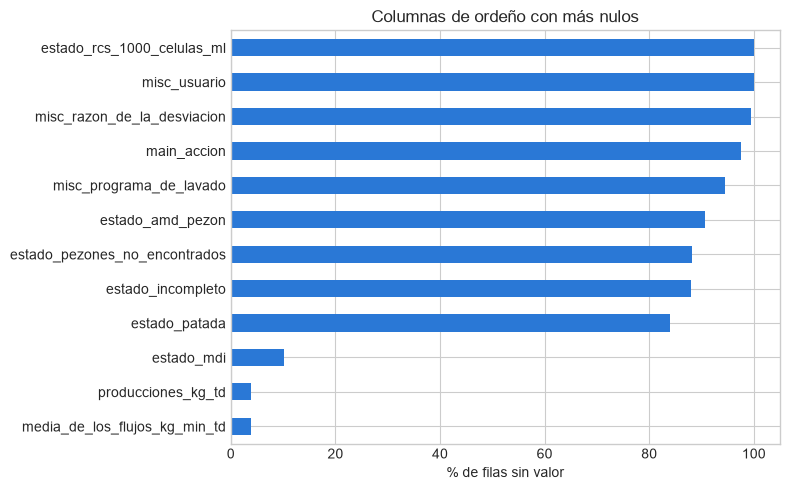

In [5]:
nulos = (ordeno[columnas_originales].isna().mean() * 100).sort_values(ascending=False)
display(nulos.head(12).round(2).rename("% nulos").to_frame())

fig, ax = plt.subplots(figsize=(8, 5))
nulos.head(12).sort_values().plot.barh(ax=ax, color=AZUL)
ax.set(xlabel="% de filas sin valor", title="Columnas de ordeño con más nulos")
plt.tight_layout()
plt.show()

Se identificaron 5285 sesiones repetidas entre los csv y xlsx usando vaca, minuto de inicio, producción y duración. Se conserva la fila xslx, pues tiene segundos de precisión. También se encontraron 2267 filas exactamente duplicadas en el archivo de ordeño. El histórico xslx no trae la acción de la visita, por lo que sus filas con producción se tratan como sesiones inferidas. También se encontraron columnas de eventos con muchos datos vacíos, por ejemplo `estado_patada` está vacía en el 84% de las filas, mientras que `estado_rcs_1000_celulas_ml` y `misc_usuario` están 100% vacías.

## 3. Producción, duración y cobertura temporal

Se muestran las sesiones de producción de 2025-2026 después de quitar las copias entre fuentes.

,count,mean,std,min,25%,50%,75%,95%,max
produccion_kg,130045.0,14.963493,5.398505,0.0,11.12,14.42,18.33,24.59,50.06
duracion_min,130045.0,8.104841,2.604929,0.666667,6.233333,7.583333,9.416667,13.15,53.65


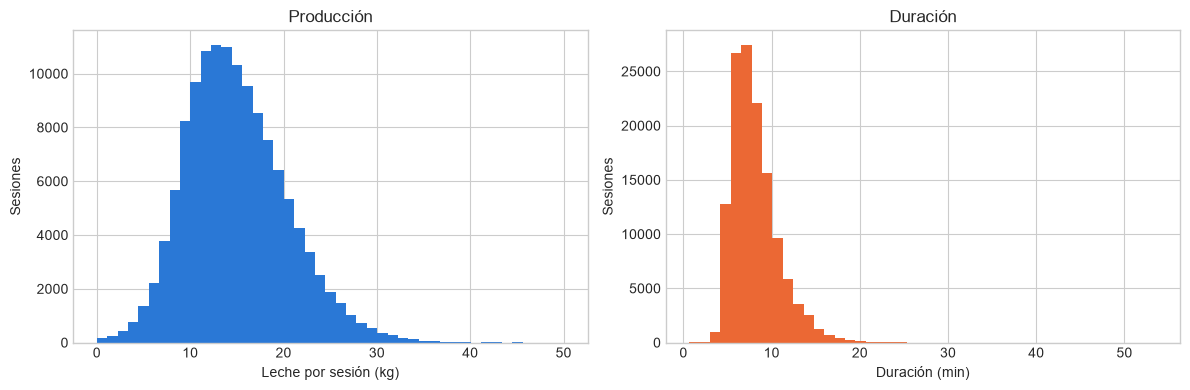

In [6]:
display(
    sesiones[["produccion_kg", "duracion_min"]]
    .describe(percentiles=[.25, .5, .75, .95]).T.round(2)
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(sesiones["produccion_kg"].dropna(), bins=45, color=AZUL)
axes[0].set(xlabel="Leche por sesión (kg)", ylabel="Sesiones", title="Producción")
axes[1].hist(sesiones["duracion_min"].dropna(), bins=45, color=NARANJA)
axes[1].set(xlabel="Duración (min)", ylabel="Sesiones", title="Duración")
plt.tight_layout()
plt.show()

,sesiones,vacas
inicio,,
2025-02-01,8266,122
2025-03-01,9601,140
2025-04-01,9011,146
2025-05-01,10155,143
2025-06-01,10058,151
2025-07-01,10120,151
2025-08-01,10153,148
2025-09-01,10400,153
2025-10-01,10616,163


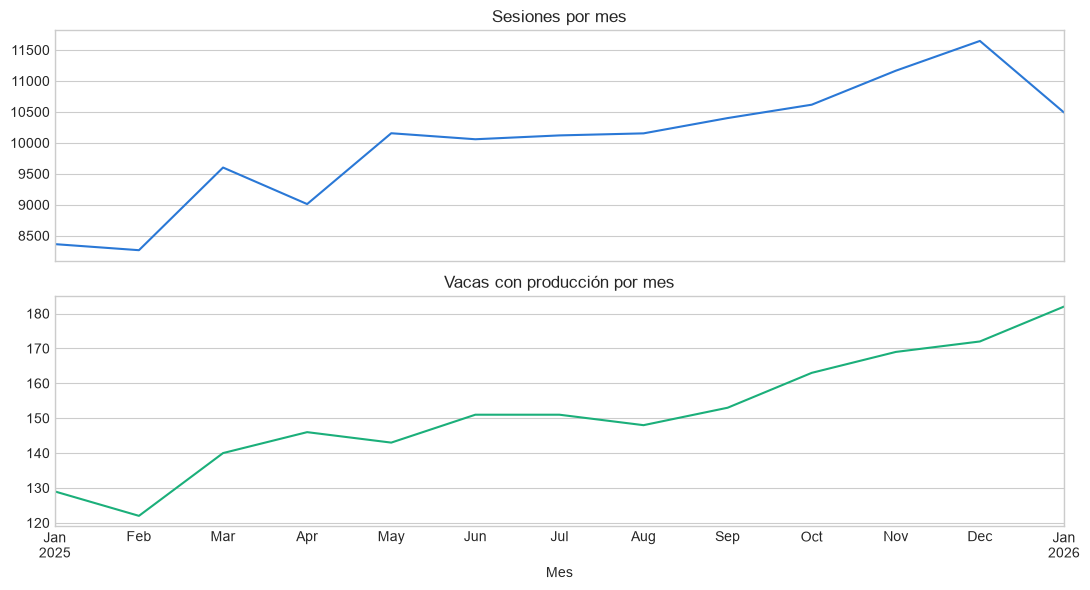

In [7]:
mensual = (sesiones.groupby(sesiones["inicio"].dt.to_period("M")).agg(sesiones=("id_vaca", "size"), vacas=("id_vaca", "nunique")))
mensual.index = mensual.index.to_timestamp()
display(mensual.tail(12))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
mensual["sesiones"].plot(ax=axes[0], color=AZUL, title="Sesiones por mes")
mensual["vacas"].plot(ax=axes[1], color=VERDE, title="Vacas con producción por mes")
axes[1].set(xlabel="Mes")
plt.tight_layout()
plt.show()

La sesión típica produce 14.4 kg y dura 7.6 minutos ( según las medianas). Se encontró que hay valores extremos, pues existen sesiones con 0 kg y sesiones de hasta 53.65 minutos, cuando el 95% dura menos de 13.15 minutos. Estas sesiones largas son de interés para detectar anomalías. También, el número de vacas que se ordeñan cada mes creció de 122 (febrero 2025) a 182 (enero 2026).

## 4. Eventos y uso de las máquinas

Se revisan tres señales de evento y el tiempo entre el fin estimado de una sesión y el inicio de la siguiente en cada máquina.

,sesiones,% de sesiones,duración mediana con evento (min),duración mediana sin evento (min)
evento,,,,
Patada,21168,16.28,8.18,7.48
Ordeño incompleto,16307,12.54,9.58,7.37
Pezón no encontrado,16535,12.71,9.95,7.32


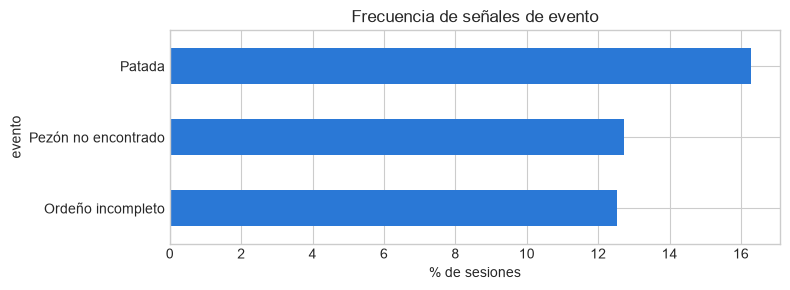

In [8]:
eventos = {
    "Patada": "estado_patada",
    "Ordeño incompleto": "estado_incompleto",
    "Pezón no encontrado": "estado_pezones_no_encontrados",
}
filas = []
for nombre, columna in eventos.items():
    hay_evento = sesiones[columna].notna()
    filas.append({
        "evento": nombre,
        "sesiones": int(hay_evento.sum()),
        "% de sesiones": round(hay_evento.mean() * 100, 2),
        "duración mediana con evento (min)": sesiones.loc[hay_evento, "duracion_min"].median(),
        "duración mediana sin evento (min)": sesiones.loc[~hay_evento, "duracion_min"].median(),
    })
resumen_eventos = pd.DataFrame(filas).set_index("evento")
display(resumen_eventos.round(2))

fig, ax = plt.subplots(figsize=(8, 3))
resumen_eventos["% de sesiones"].sort_values().plot.barh(ax=ax, color=AZUL)
ax.set(xlabel="% de sesiones", title="Frecuencia de señales de evento")
plt.tight_layout()
plt.show()

In [9]:
por_maquina = sesiones.dropna(subset=["misc_eo_po", "inicio", "duracion_min"]).copy()
por_maquina = por_maquina.sort_values(["misc_eo_po", "inicio"])
por_maquina["fin"] = por_maquina["inicio"] + pd.to_timedelta(por_maquina["duracion_min"], unit="m")
por_maquina["fin_anterior"] = por_maquina.groupby("misc_eo_po")["fin"].shift()
por_maquina["intervalo_min"] = (
    por_maquina["inicio"] - por_maquina["fin_anterior"]
).dt.total_seconds() / 60
por_maquina["intervalo_no_negativo"] = por_maquina["intervalo_min"].where(
    por_maquina["intervalo_min"].ge(0)
)
display(
    por_maquina.groupby("misc_eo_po").agg(
        sesiones=("id_vaca", "size"),
        duracion_mediana_min=("duracion_min", "median"),
        intervalo_mediano_min=("intervalo_no_negativo", "median"),
    ).round(2)
)
print("Intervalos negativos (posibles solapamientos o precisión distinta):",
      por_maquina["intervalo_min"].lt(0).sum())

,sesiones,duracion_mediana_min,intervalo_mediano_min
misc_eo_po,,,
486cc6e5,42790,7.57,0.53
9210048d,44450,7.5,0.67
aa845187,42805,7.72,0.58


Intervalos negativos (posibles solapamientos o precisión distinta): 1062


Se encontró también que los eventos alargan las sesiones, pues con un ordeño incompleto, la sesión dura 2.2 minutos más (mediana), con un pezón no encontrado 2.6 minutos más, y con una patada solo 0.7 minutos más. Esto reafirma la idea de que los eventos aumentan el tiempo de ocupación del robot. Así mismo, en cada máquina, entre que termina una sesión y empieza la siguiente pasan en la mediana entre 0.53 y 0.67 minutos, y esto podrían ser vacas esperando turno, sin embargo, los datos no registran tiempos de espera, así que no se puede medir la cola directamente. Por último, hay 1062 casos en que una sesión empieza antes de que termine la anterior. Estos pueden venir de la mezcla de horas con y sin segundos, o ser errores de registro.

## 5. Cobertura y calidad del concentrado

Cada fila corresponde a un registro de consumo

In [10]:
vacas_ordeno = set(sesiones["id_vaca"].dropna())
vacas_concentrado = set(concentrado["id_vaca"].dropna())
print(f"Vacas con sesiones: {len(vacas_ordeno)}")
print(f"Vacas con concentrado: {len(vacas_concentrado)}")
print(f"Vacas compartidas: {len(vacas_ordeno & vacas_concentrado)}")
print(f"Vacas con sesiones y sin concentrado: {len(vacas_ordeno - vacas_concentrado)}")
print("Fechas sin interpretar:", concentrado["hora_evento"].isna().sum())
print("Consumos nulos:", concentrado["consumido"].isna().sum())
display(concentrado["consumido"].describe(percentiles=[.25, .5, .75]).round(2).to_frame("consumido"))

Vacas con sesiones: 207
Vacas con concentrado: 202
Vacas compartidas: 201
Vacas con sesiones y sin concentrado: 6
Fechas sin interpretar: 0
Consumos nulos: 0


,consumido
count,129532.00
mean,1.10
std,0.58
min,0.00
25%,0.66
50%,1.08
75%,1.50
max,4.72


Hay 207 vacas con sesiones de ordeño y 202 con registros de concentrado. 201 vacas aparecen en ambos archivos. Seis vacas con sesiones no tienen registros de concentrado, y una vaca con concentrado no tiene sesiones. El consumo por registro tiene una mediana de 1.08 (falta confirmar la unidad, probablemente kg) y no hay valores faltantes.

## 6. Relación diaria entre concentrado y leche

Para analizar si existe una relación entre el concentrado consumido y su producción de leche, se utiliza el "día pareado", el cual es cualquier fecha donde una vaca tiene tanto datos de leche como de concentrado. Por ejemplo, si en un día una vaca tuvo dos ordeños y tres registros de alimento, las sumas forman una sola fila. Los días sin alguna de las dos medidas quedan fuera, no se cuentan como consumo cero.

In [11]:
leche_dia = (
    sesiones.dropna(subset=["fecha", "produccion_kg"])
    .groupby(["id_vaca", "fecha"])
    .agg(leche_kg=("produccion_kg", "sum"), sesiones=("produccion_kg", "size"))
    .reset_index()
)
consumo_dia = (
    concentrado.dropna(subset=["fecha", "consumido"])
    .loc[lambda df: df["id_vaca"].isin(vacas_ordeno) & df["fecha"].ge("2025-01-01") & df["fecha"].lt("2027-01-01")]
    .groupby(["id_vaca", "fecha"])
    .agg(consumo=("consumido", "sum"), eventos_concentrado=("consumido", "size"))
    .reset_index()
)
pareados = leche_dia.merge(
    consumo_dia, on=["id_vaca", "fecha"], how="inner", validate="one_to_one"
)
print(f"Días vaca con leche: {len(leche_dia):,}")
print(f"Días vaca con concentrado: {len(consumo_dia):,}")
print(f"Días vaca pareados: {len(pareados):,} | Vacas: {pareados['id_vaca'].nunique()}")
display(pareados.head())

Días vaca con leche: 53,838
Días vaca con concentrado: 50,010
Días vaca pareados: 49,981 | Vacas: 201


,id_vaca,fecha,leche_kg,sesiones,consumo,eventos_concentrado
0,00705ea8,2025-04-29,24.92,2,2.284,2
1,00705ea8,2025-04-30,40.17,3,4.192,3
2,00705ea8,2025-05-01,27.43,2,3.177,3
3,00705ea8,2025-05-02,47.56,2,2.752,2
4,00705ea8,2025-05-03,63.59,3,5.416,3


Correlación diaria global: 0.585
Correlación diaria tras restar la media de cada vaca: 0.655


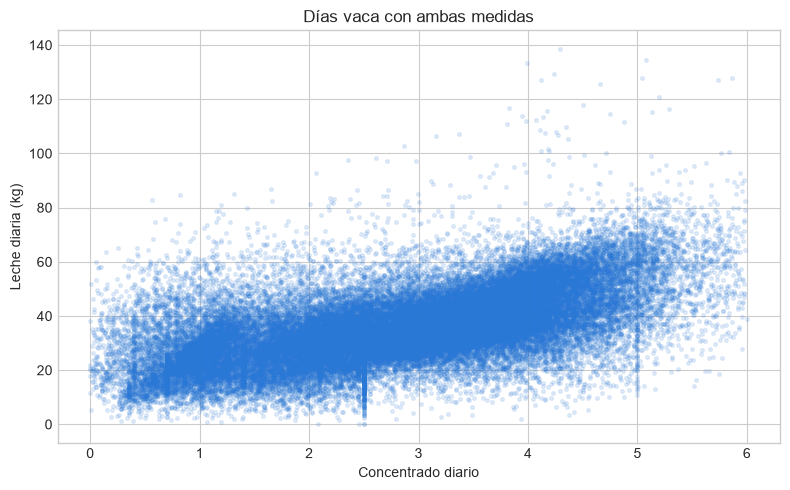

In [12]:
correlacion_global = pareados["consumo"].corr(pareados["leche_kg"])
centrado = pareados[["id_vaca", "consumo", "leche_kg"]].copy()
for columna in ["consumo", "leche_kg"]:
    centrado[columna] -= centrado.groupby("id_vaca")[columna].transform("mean")
correlacion_dentro_vaca = centrado["consumo"].corr(centrado["leche_kg"])
print(f"Correlación diaria global: {correlacion_global:.3f}")
print(f"Correlación diaria tras restar la media de cada vaca: {correlacion_dentro_vaca:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(pareados["consumo"], pareados["leche_kg"], s=7, alpha=.13, color=AZUL)
ax.set(xlabel="Concentrado diario", ylabel="Leche diaria (kg)", title="Días vaca con ambas medidas")
plt.tight_layout()
plt.show()

Obtuvimos 49,981 días vaca con ambas medidas, de 201 vacas. Existe una relación positiva, pues los días en que una vaca consume más concentrado también produce más leche (r = 0.585). La relación se mantiene al comparar cada vaca consigo misma, es decir, quitando el efecto de que unas vacas siempre produzcan más que otras (r = 0.655). Sin embargo, esto no prueba que el concentrado cause más producción, pues ambas medidas podrían aumentar simplemente porque la vaca visitó más veces el robot ese día. También pueden influir la etapa de lactancia o la salud de la vaca.

## 7. Relación consumo-leche por vaca y entre días

Primero se analiza cada vaca por separado para comprobar si la relación positiva entre concentrado y producción observada en todo el conjunto también aparece dentro de cada animal. Posteriormente, se compara el concentrado consumido un día con la leche producida al día siguiente. Esto permite revisar si la asociación observada el mismo día también se mantiene con un desfase de un día. Al final se revisa la precisión de las horas registradas en el archivo de concentrado.

Días pareados por vaca: mediana 275; rango 2-366
Correlación del mismo día por vaca (200 vacas): mediana 0.677; rango intercuartílico 0.545-0.774


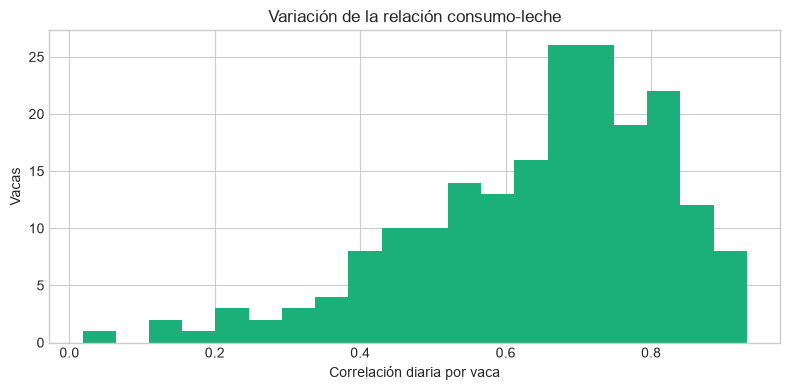

Consumo del día anterior y leche actual, correlación global: r = 0.221
Consumo del día anterior y leche actual por vaca: mediana r = 0.068
Registros de concentrado a la hora en punto: 129,532 de 129,532


In [13]:
dias_por_vaca = pareados.groupby("id_vaca").size()

correlaciones_mismo_dia = (
    pareados.groupby("id_vaca")[["consumo", "leche_kg"]]
    .apply(
        lambda datos: datos["consumo"].corr(datos["leche_kg"])
        if len(datos) >= 10 else np.nan
    )
    .dropna()
)

print(
    f"Días pareados por vaca: mediana {dias_por_vaca.median():.0f}; "
    f"rango {dias_por_vaca.min()}-{dias_por_vaca.max()}"
)
print(
    f"Correlación del mismo día por vaca ({len(correlaciones_mismo_dia)} vacas): "
    f"mediana {correlaciones_mismo_dia.median():.3f}; "
    f"rango intercuartílico "
    f"{correlaciones_mismo_dia.quantile(.25):.3f}-"
    f"{correlaciones_mismo_dia.quantile(.75):.3f}"
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(correlaciones_mismo_dia, bins=20, color=VERDE)
ax.set(
    xlabel="Correlación diaria por vaca",
    ylabel="Vacas",
    title="Variación de la relación consumo-leche",
)
plt.tight_layout()
plt.show()

# Para comparar el consumo de ayer con la leche de hoy,
# se mueve la fecha del consumo un día hacia adelante.
consumo_anterior = consumo_dia[["id_vaca", "fecha", "consumo"]].copy()
consumo_anterior["fecha"] += pd.Timedelta(days=1)

desfase = leche_dia.merge(
    consumo_anterior,
    on=["id_vaca", "fecha"],
    how="inner",
    validate="one_to_one",
)

correlaciones_dia_anterior = (
    desfase.groupby("id_vaca")[["consumo", "leche_kg"]]
    .apply(
        lambda datos: datos["consumo"].corr(datos["leche_kg"])
        if len(datos) >= 10 else np.nan
    )
    .dropna()
)

print(
    f"Consumo del día anterior y leche actual, correlación global: "
    f"r = {desfase['consumo'].corr(desfase['leche_kg']):.3f}"
)
print(
    f"Consumo del día anterior y leche actual por vaca: "
    f"mediana r = {correlaciones_dia_anterior.median():.3f}"
)

hora_en_punto = (
    concentrado["hora_evento"].dt.minute.eq(0)
    & concentrado["hora_evento"].dt.second.eq(0)
)
print(
    f"Registros de concentrado a la hora en punto: "
    f"{hora_en_punto.sum():,} de {len(concentrado):,}"
)

Cada vaca tiene una mediana de 275 días con ambas medidas. En 200 vacas (las que tienen al menos 10 días), la correlación del mismo día tiene una mediana de 0.677, y la mitad de las vacas está entre 0.545 y 0.774. En el caso de un día de desfase, el concentrado de ayer casi no se relaciona con la leche de hoy, pues la correlación global es 0.221 y, dentro de cada vaca, la mediana es 0.068. La asociación ocurre el mismo día, lo que podría generar la hipótesis de que ambas medidas dependen de las visitas de ese mismo día. No obstante, todos los registros de concentrado (129532) están a la hora en punto, por lo que no podemos asociar un consumo a una sesión de ordeño específica, solo a días o a horas.

## 8. Conclusiones del Data Understanding

Contamos con 130045 sesiones de 207 vacas en tres robots, cada una con duración, producción y tres señales de evento: patada, ordeño incompleto y pezón no encontrado.

Normalmente, los ordeños incompletos y los pezones no encontrados alargan la sesión más de 2 minutos, y además los robots casi no tienen tiempo libre entre sesiones. También, hubo un incremento en la cantidad de vacas de 122 a 182 con las mismas tres máquinas.

Algo a destacar es que lso eventos aparecen solo en el 12-16% de las sesiones, por lo que el accuracy tal vez no sea una buena medida para el proyecto, pues un modelo que siempre saque "sin evento" superaría el 80%.